<a href="https://colab.research.google.com/github/Daffahafizh15/DaffaHafizhL_G211240054_FrameworkSMT3/blob/framework/Daffa_G211240054_TransformasiCitra_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum 2 – Transformasi Geometris Citra
**Nama:** Daffa Hafizh Laksono  
**NIM:** G.211.24.0054  
**Mata Kuliah:** Pengolahan Citra Digital

Fungsi yang dibuat: Translasi, Rotasi, Scaling, Shearing, Refleksi, Affine, dan Proyektif (Perspective).  
Ketentuan: citra hewan dibaca dari folder dataset (minimal 20 citra), dikonversi ke grayscale, lalu diberi semua transformasi.

## 1. Import & Konfigurasi

In [1]:
import os, glob
import cv2
import numpy as np
from matplotlib import pyplot as plt

# ====== UBAH SESUAI LOKASI DATASET ======
DATASET_DIR   = "/content/dataset_hewan"   # folder dataset (otomatis dibuat)
BACKUP_DRIVE  = "/content/drive/My Drive/dataset_hewan"   # salinan agar tidak unduh ulang
AUTO_DOWNLOAD = True    # False jika memakai dataset sendiri/dari dosen di DATASET_DIR
OUTPUT_DIR    = "hasil_transformasi"
MIN_CITRA     = 20

# Mount Google Drive (dilewati otomatis jika tidak dijalankan di Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Bukan di Colab, mount Drive dilewati.")

Mounted at /content/drive


## 2. Siapkan Dataset (20+ Foto Hewan)
Cell ini mengunduh 1 foto per jenis hewan secara otomatis. Jika folder `BACKUP_DRIVE` di Google Drive sudah berisi dataset, isinya langsung disalin sehingga tidak perlu mengunduh ulang. Jika memakai dataset sendiri, set `AUTO_DOWNLOAD = False` dan arahkan `DATASET_DIR` ke folder tersebut.

In [2]:
import shutil, subprocess, sys

def hitung_citra(folder):
    if not os.path.isdir(folder):
        return 0
    return len([f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))])

if AUTO_DOWNLOAD and hitung_citra(DATASET_DIR) < MIN_CITRA:
    # 1) Coba pulihkan dari Drive
    if hitung_citra(BACKUP_DRIVE) >= MIN_CITRA:
        shutil.copytree(BACKUP_DRIVE, DATASET_DIR, dirs_exist_ok=True)
        print("Dataset disalin dari Drive.")
    else:
        # 2) Unduh dari internet (Bing via icrawler)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "icrawler"], check=True)
        from icrawler.builtin import BingImageCrawler
        os.makedirs(DATASET_DIR, exist_ok=True)

        hewan = ["cat", "dog", "horse", "elephant", "lion", "tiger", "eagle", "giraffe",
                 "zebra", "panda", "rabbit", "deer", "monkey", "turtle", "goldfish",
                 "cow", "goat", "duck", "rooster", "butterfly", "owl", "penguin",
                 "koala", "parrot", "dolphin", "fox"]   # cadangan jika ada yang gagal

        for h in hewan:
            if hitung_citra(DATASET_DIR) >= MIN_CITRA + 2:
                break
            try:
                BingImageCrawler(storage={"root_dir": DATASET_DIR},
                                 feeder_threads=1, parser_threads=1, downloader_threads=2
                                 ).crawl(keyword=f"{h} animal photo", max_num=1,
                                         min_size=(200, 200), file_idx_offset="auto")
            except Exception as e:
                print("Gagal unduh", h, "->", e)

        # 3) Backup ke Drive (jika Drive ter-mount)
        if os.path.isdir("/content/drive/My Drive") and hitung_citra(DATASET_DIR) >= MIN_CITRA:
            shutil.copytree(DATASET_DIR, BACKUP_DRIVE, dirs_exist_ok=True)
            print("Backup dataset disimpan di:", BACKUP_DRIVE)

print("Jumlah citra di dataset:", hitung_citra(DATASET_DIR))

Dataset disalin dari Drive.
Jumlah citra di dataset: 22


## 3. Load Dataset & Konversi Grayscale
Semua citra di folder dibaca, lalu dikonversi ke grayscale. Program berhenti dengan pesan jelas jika citra kurang dari 20.

In [3]:
def load_dataset(folder, minimal=20):
    ekstensi = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff")
    paths = []
    for e in ekstensi:
        paths += glob.glob(os.path.join(folder, e))
        paths += glob.glob(os.path.join(folder, e.upper()))
    paths = sorted(set(paths))

    data = []
    for p in paths:
        bgr = cv2.imread(p)
        if bgr is None:
            print("Gagal dibaca, dilewati:", p)
            continue
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)   # konversi ke grayscale
        data.append((os.path.basename(p), gray))

    assert len(data) >= minimal, f"Citra hanya {len(data)}, minimal harus {minimal}. Cek DATASET_DIR."
    return data

dataset = load_dataset(DATASET_DIR, MIN_CITRA)
print(f"Jumlah citra dimuat : {len(dataset)}")
print(f"Contoh              : {dataset[0][0]}, ukuran (tinggi, lebar) = {dataset[0][1].shape}")

Jumlah citra dimuat : 22
Contoh              : 000001.jpg, ukuran (tinggi, lebar) = (1060, 1600)


## 4. Fungsi Transformasi Geometris

In [4]:
def _warp_expand(img, M):
    """warpAffine dengan kanvas diperluas agar seluruh hasil tidak terpotong."""
    h, w = img.shape[:2]
    sudut = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    baru = cv2.transform(sudut[None], M)[0]
    x_min, y_min = baru.min(axis=0)
    x_max, y_max = baru.max(axis=0)
    M2 = M.copy()
    M2[0, 2] -= x_min
    M2[1, 2] -= y_min
    lebar_baru, tinggi_baru = int(np.ceil(x_max - x_min)), int(np.ceil(y_max - y_min))
    return cv2.warpAffine(img, M2, (lebar_baru, tinggi_baru))


def translasi(img, tx=50, ty=30):
    """1. Translasi: geser citra tx piksel ke kanan dan ty piksel ke bawah."""
    h, w = img.shape[:2]
    M = np.float32([[1, 0, tx],
                    [0, 1, ty]])
    return cv2.warpAffine(img, M, (w, h))


def rotasi(img, sudut=45, skala=1.0, expand=True):
    """2. Rotasi: putar citra sebesar 'sudut' derajat (positif = berlawanan arah jarum jam)."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, skala)
    if expand:
        return _warp_expand(img, M)
    return cv2.warpAffine(img, M, (w, h))


def scaling(img, fx=1.5, fy=1.5):
    """3. Scaling: perbesar (>1) atau perkecil (<1) citra."""
    interp = cv2.INTER_AREA if (fx < 1 or fy < 1) else cv2.INTER_LINEAR
    return cv2.resize(img, None, fx=fx, fy=fy, interpolation=interp)


def shearing(img, shx=0.3, shy=0.0):
    """4. Shearing: x' = x + shx*y ; y' = y + shy*x."""
    M = np.float32([[1, shx, 0],
                    [shy, 1, 0]])
    return _warp_expand(img, M)


def refleksi(img, mode="horizontal"):
    """5. Refleksi: 'horizontal', 'vertical', atau 'both'."""
    kode = {"horizontal": 1, "vertical": 0, "both": -1}
    if mode not in kode:
        raise ValueError("mode harus 'horizontal', 'vertical', atau 'both'")
    return cv2.flip(img, kode[mode])


def affine(img, src=None, dst=None):
    """6. Affine: 3 titik asal dipetakan ke 3 titik tujuan.
    Titik default dibuat proporsional terhadap ukuran citra."""
    h, w = img.shape[:2]
    if src is None:
        src = np.float32([[0.1*w, 0.1*h], [0.9*w, 0.1*h], [0.1*w, 0.9*h]])
    if dst is None:
        dst = np.float32([[0.05*w, 0.25*h], [0.85*w, 0.10*h], [0.25*w, 0.95*h]])
    M = cv2.getAffineTransform(np.float32(src), np.float32(dst))
    return cv2.warpAffine(img, M, (w, h))


def proyektif(img, src=None, dst=None):
    """7. Proyektif (perspective): 4 titik asal dipetakan ke 4 titik tujuan.
    Titik default proporsional terhadap ukuran citra."""
    h, w = img.shape[:2]
    if src is None:
        src = np.float32([[0, 0], [w, 0], [0, h], [w, h]])
    if dst is None:
        dst = np.float32([[0.15*w, 0.10*h], [0.90*w, 0.00*h],
                          [0.00*w, 0.90*h], [0.85*w, 1.00*h]])
    M = cv2.getPerspectiveTransform(np.float32(src), np.float32(dst))
    return cv2.warpPerspective(img, M, (w, h))

## 5. Terapkan Semua Transformasi ke Seluruh Dataset
Setiap citra grayscale diproses dengan 7 transformasi, hasilnya disimpan ke folder output per jenis transformasi.

In [5]:
TRANSFORMASI = {
    "Translasi":          lambda im: translasi(im, tx=50, ty=30),
    "Rotasi 45°":         lambda im: rotasi(im, sudut=45),
    "Scaling 0.5x":       lambda im: scaling(im, 0.5, 0.5),
    "Shearing":           lambda im: shearing(im, shx=0.3),
    "Refleksi Horizontal":lambda im: refleksi(im, "horizontal"),
    "Affine":             lambda im: affine(im),
    "Proyektif":          lambda im: proyektif(im),
}

hasil = {}   # hasil[nama_file][nama_transformasi] = citra hasil
for nama, gray in dataset:
    hasil[nama] = {k: fn(gray) for k, fn in TRANSFORMASI.items()}

# Simpan ke folder
for nama, d in hasil.items():
    for k, im in d.items():
        sub = os.path.join(OUTPUT_DIR, k.replace(" ", "_").replace("°", ""))
        os.makedirs(sub, exist_ok=True)
        cv2.imwrite(os.path.join(sub, nama), im)

total = len(hasil) * len(TRANSFORMASI)
print(f"{len(hasil)} citra x {len(TRANSFORMASI)} transformasi = {total} hasil, disimpan di '{OUTPUT_DIR}/'")

22 citra x 7 transformasi = 154 hasil, disimpan di 'hasil_transformasi/'


## 6. Visualisasi Hasil
### 6.1 Contoh 3 citra pertama – semua transformasi

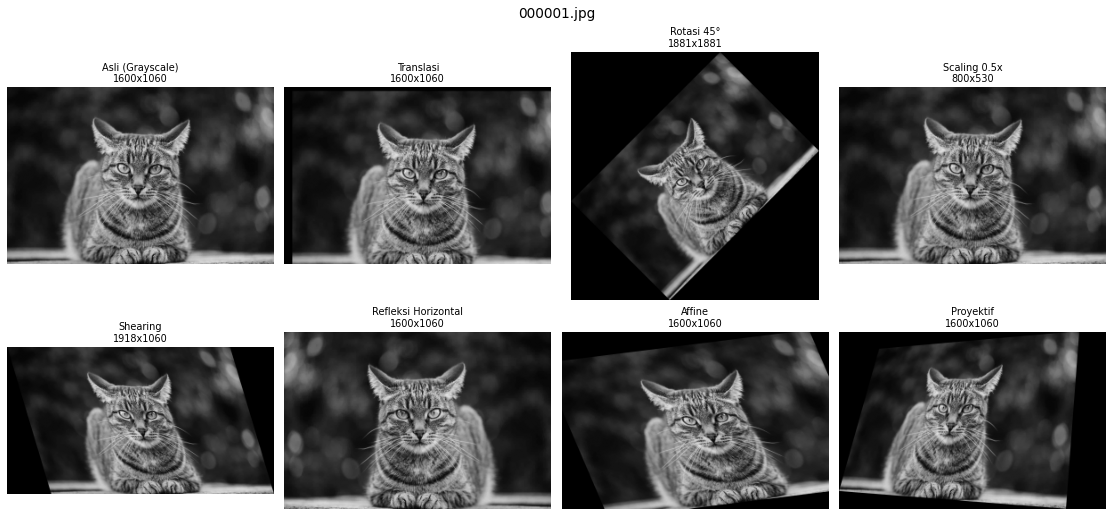

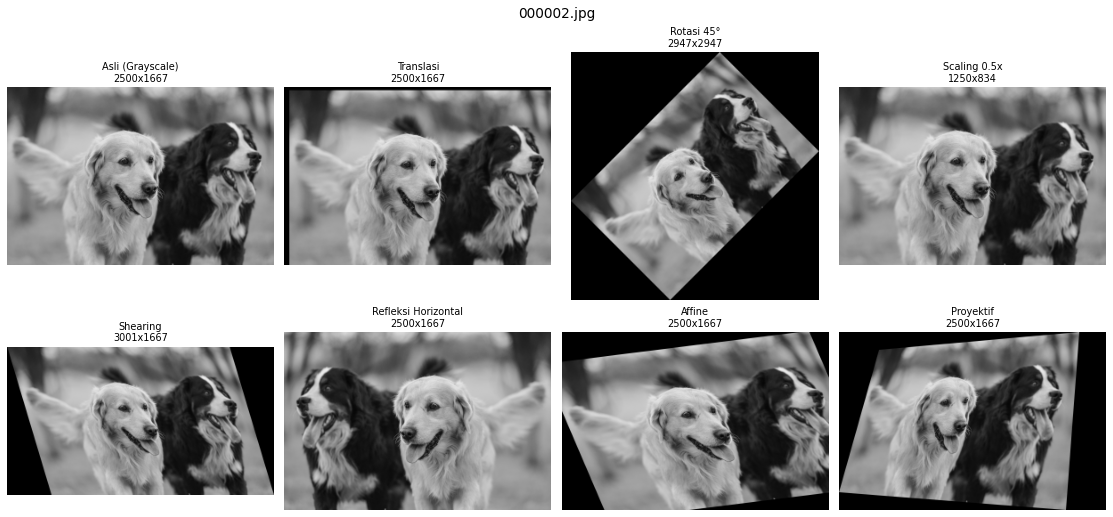

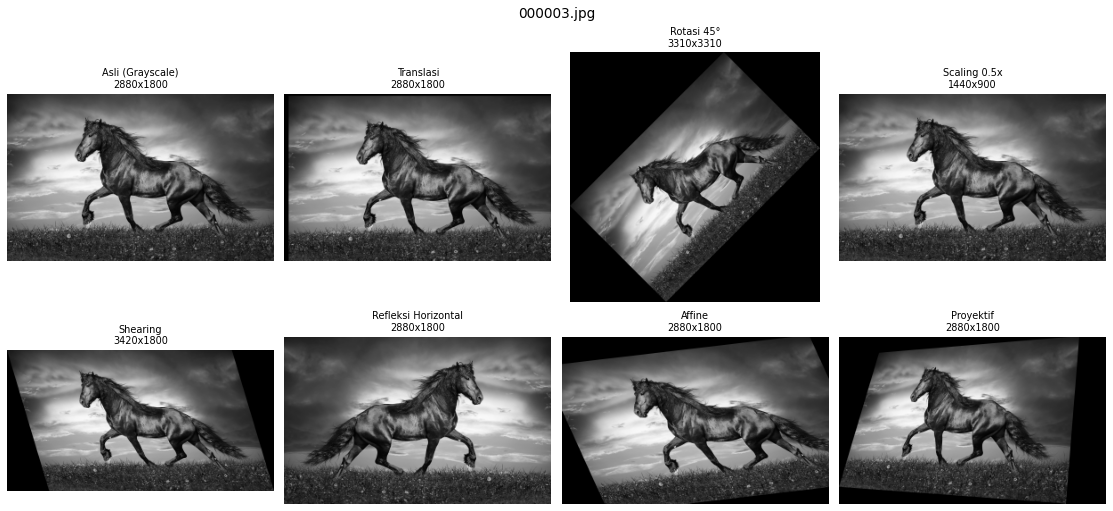

In [6]:
def kecilkan(im, maks=300):
    """Perkecil hanya untuk TAMPILAN agar ukuran notebook ringan (hasil asli tetap utuh)."""
    h, w = im.shape[:2]
    s = maks / max(h, w)
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else im


def tampilkan(nama):
    gray = dict(dataset)[nama]
    items = [("Asli (Grayscale)", gray)] + list(hasil[nama].items())
    kolom = 4
    baris = int(np.ceil(len(items) / kolom))
    plt.figure(figsize=(4 * kolom, 4 * baris), dpi=70)
    for i, (judul, im) in enumerate(items, 1):
        plt.subplot(baris, kolom, i)
        plt.imshow(kecilkan(im), cmap="gray", vmin=0, vmax=255)
        plt.title(f"{judul}\n{im.shape[1]}x{im.shape[0]}", fontsize=10)
        plt.axis("off")
    plt.suptitle(nama, fontsize=14)
    plt.tight_layout()
    plt.show()

for nama, _ in dataset[:3]:
    tampilkan(nama)

### 6.2 Seluruh dataset – per jenis transformasi

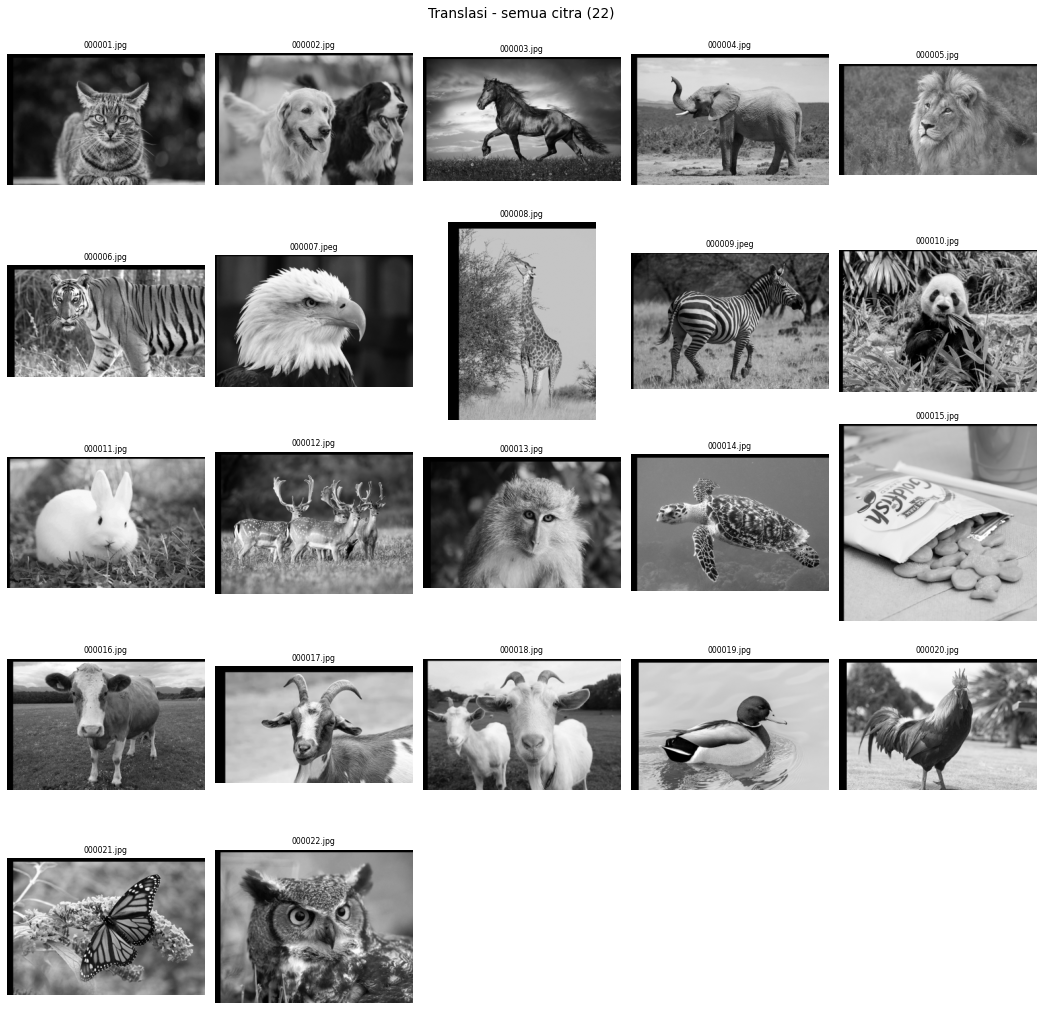

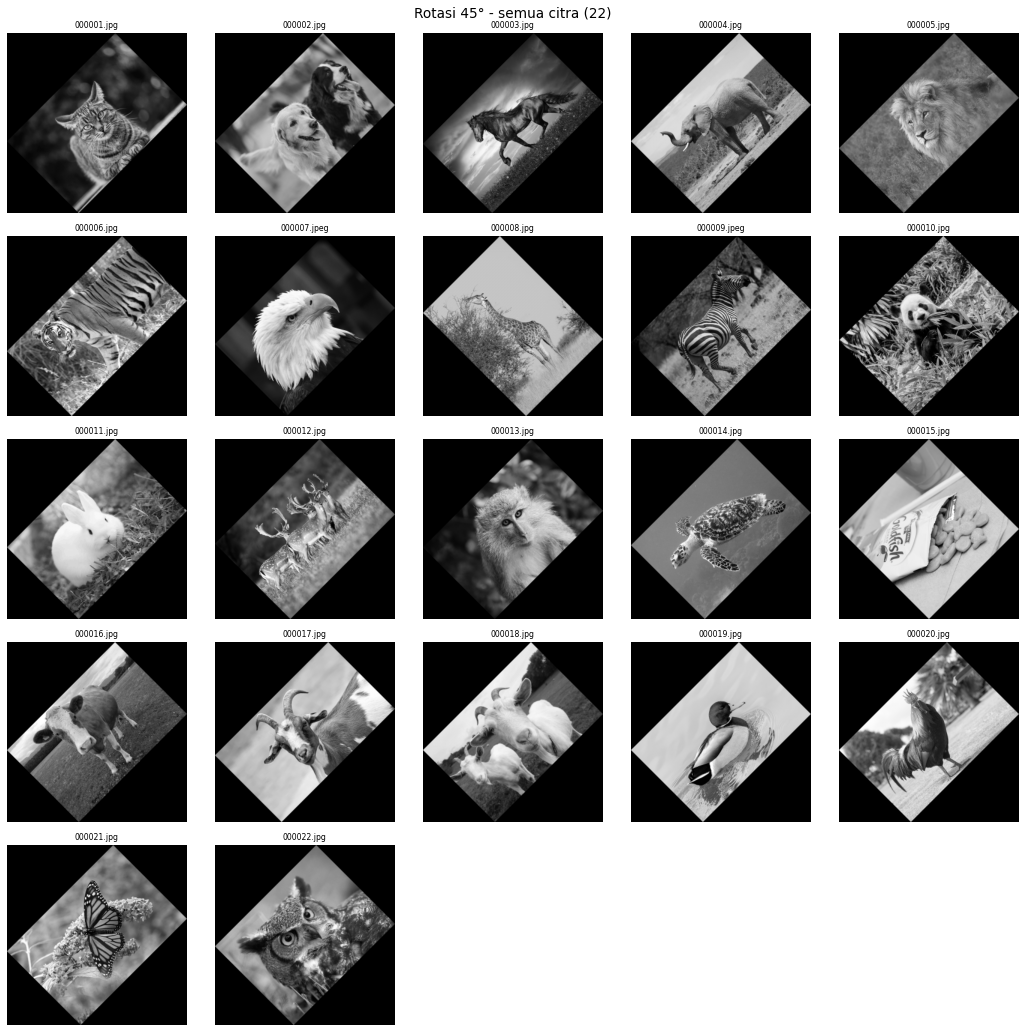

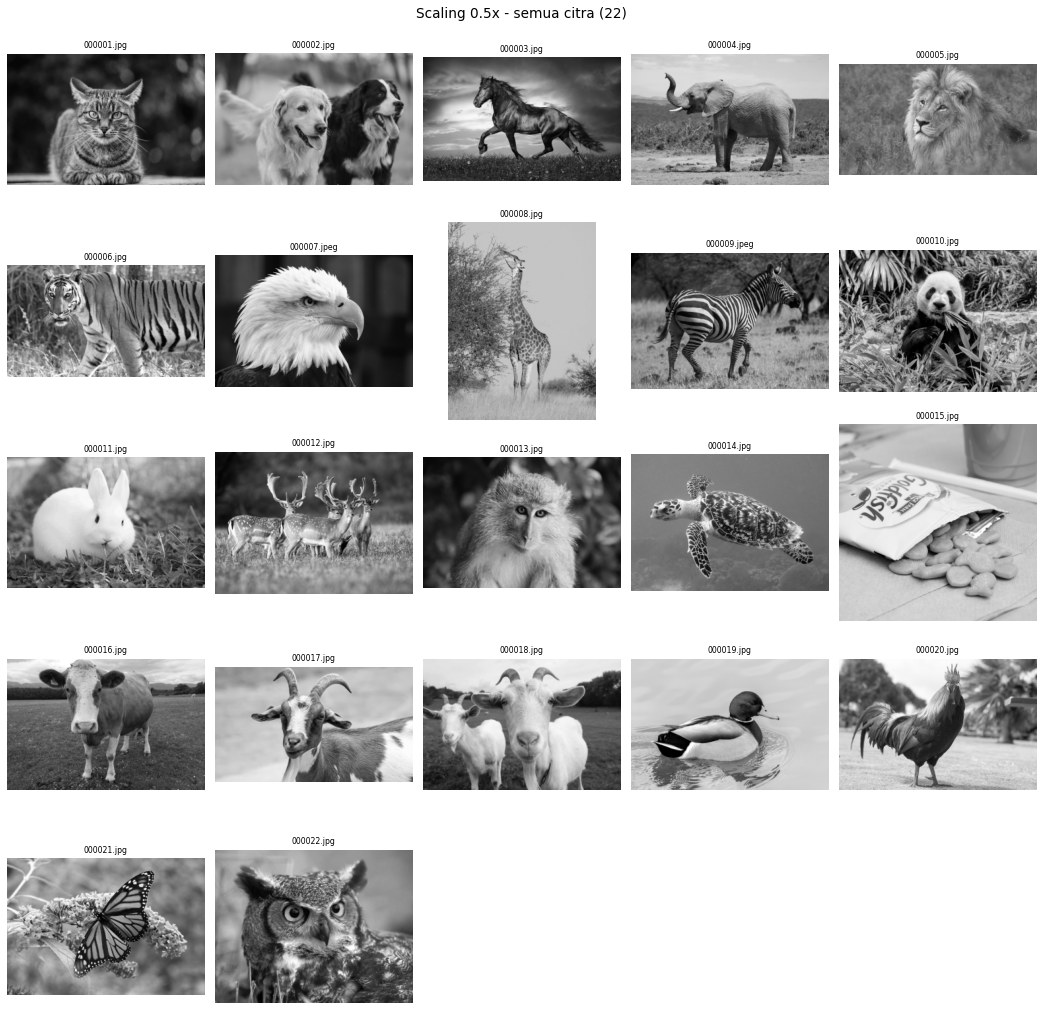

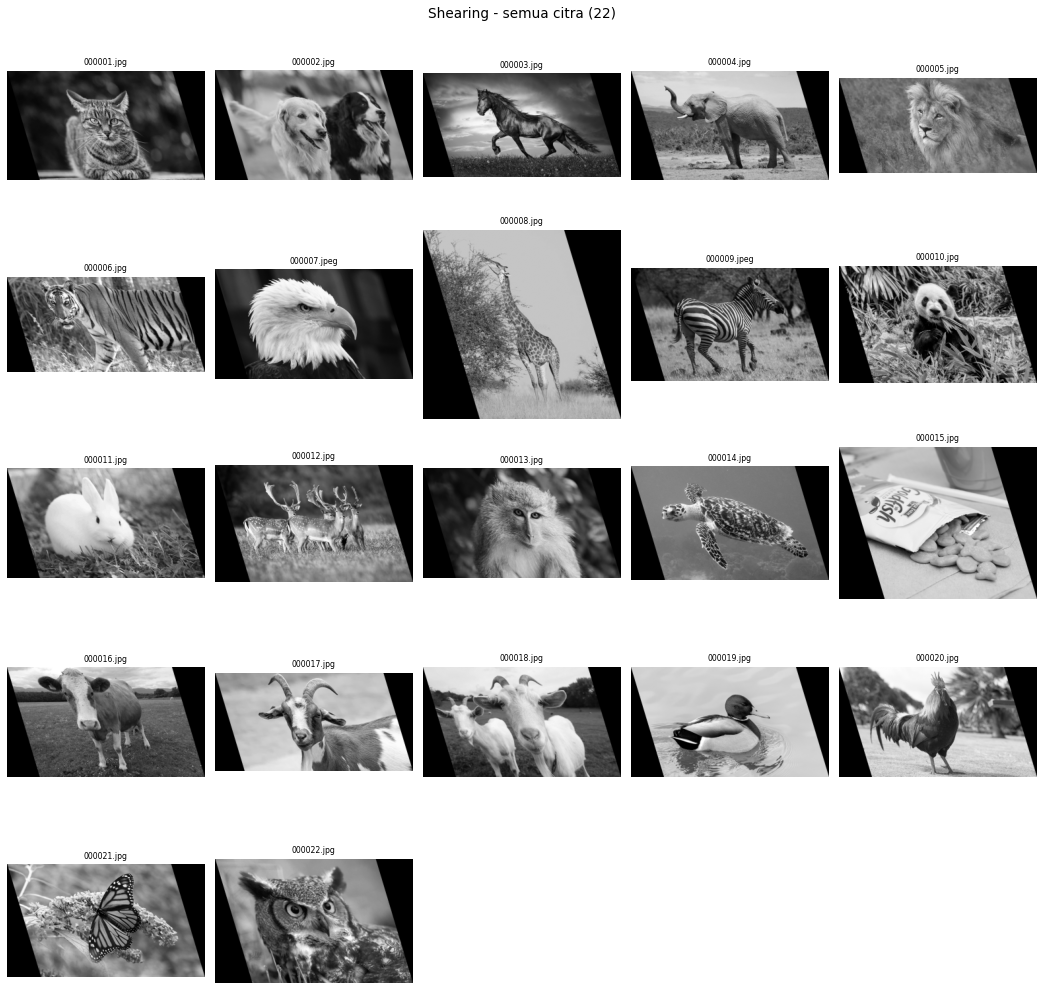

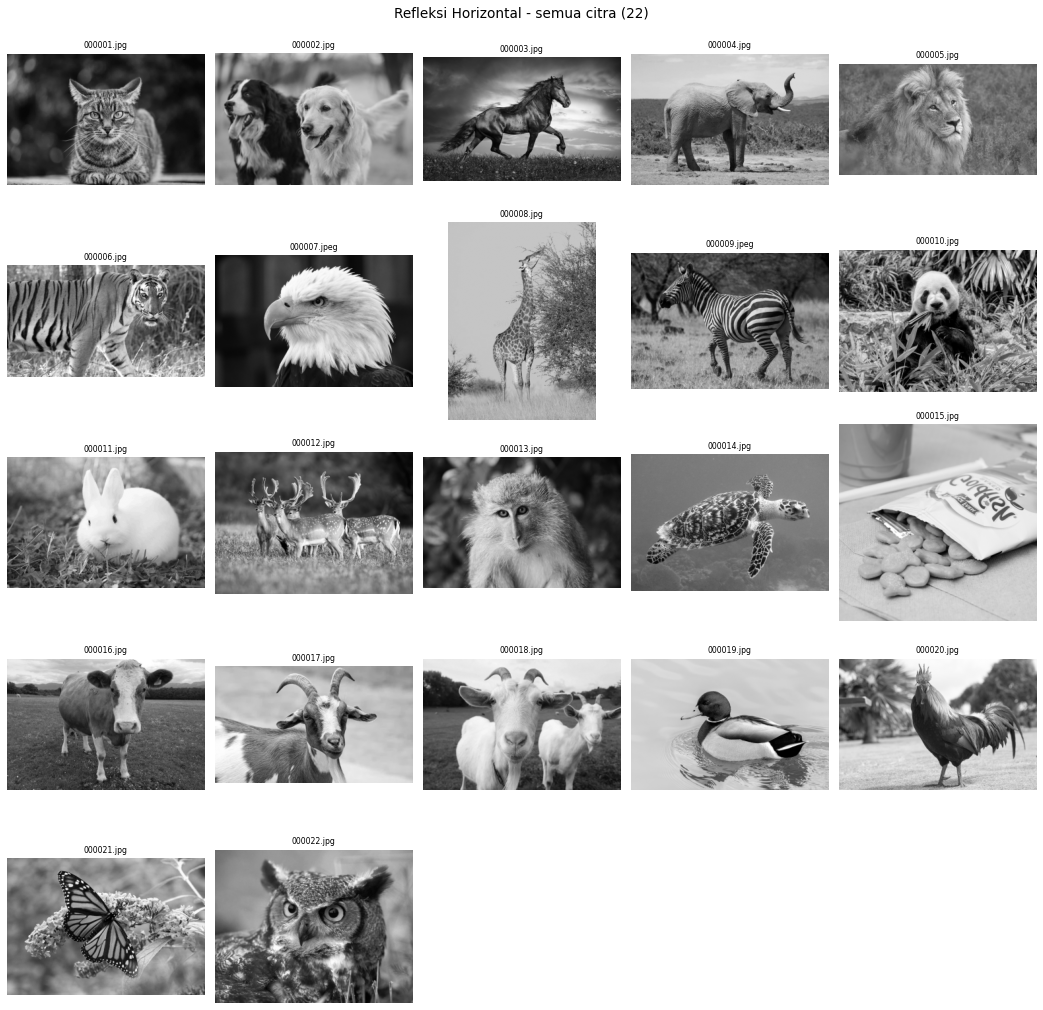

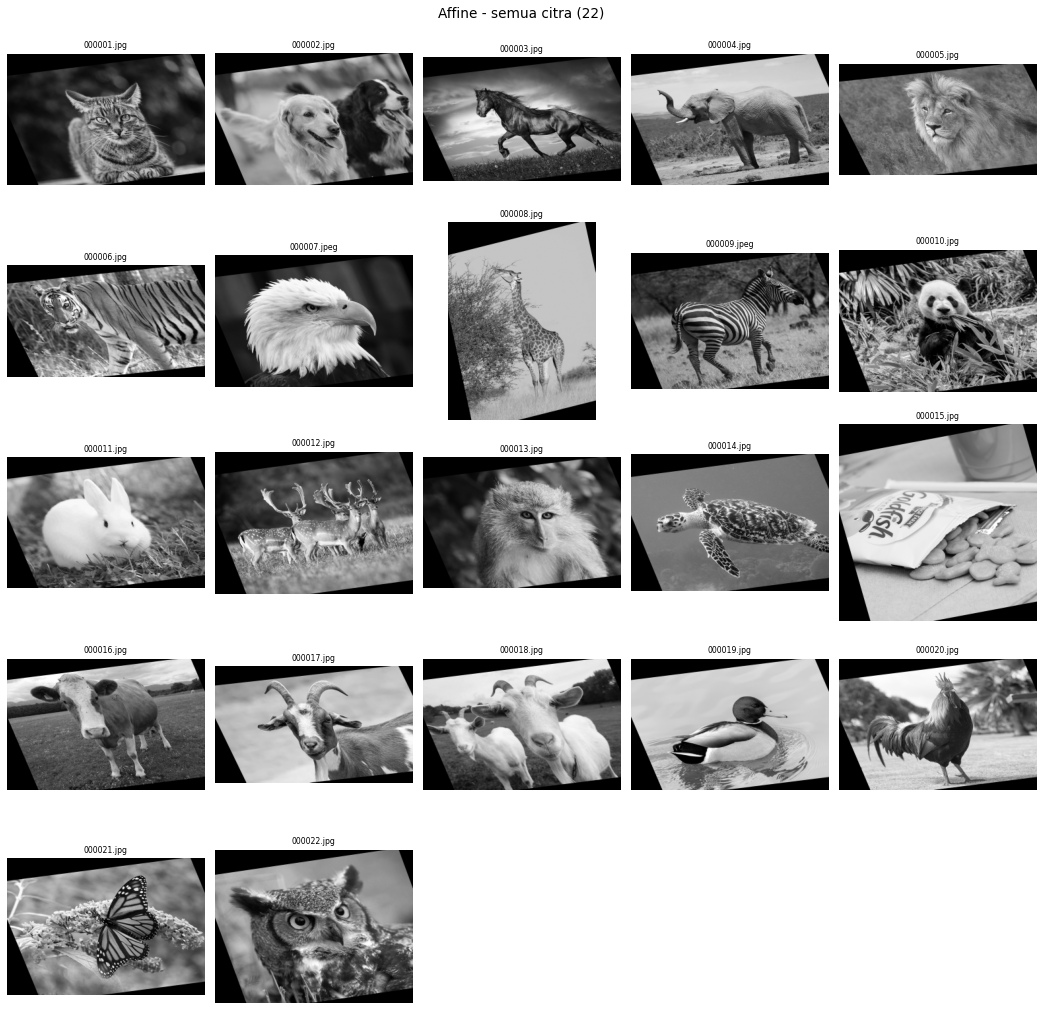

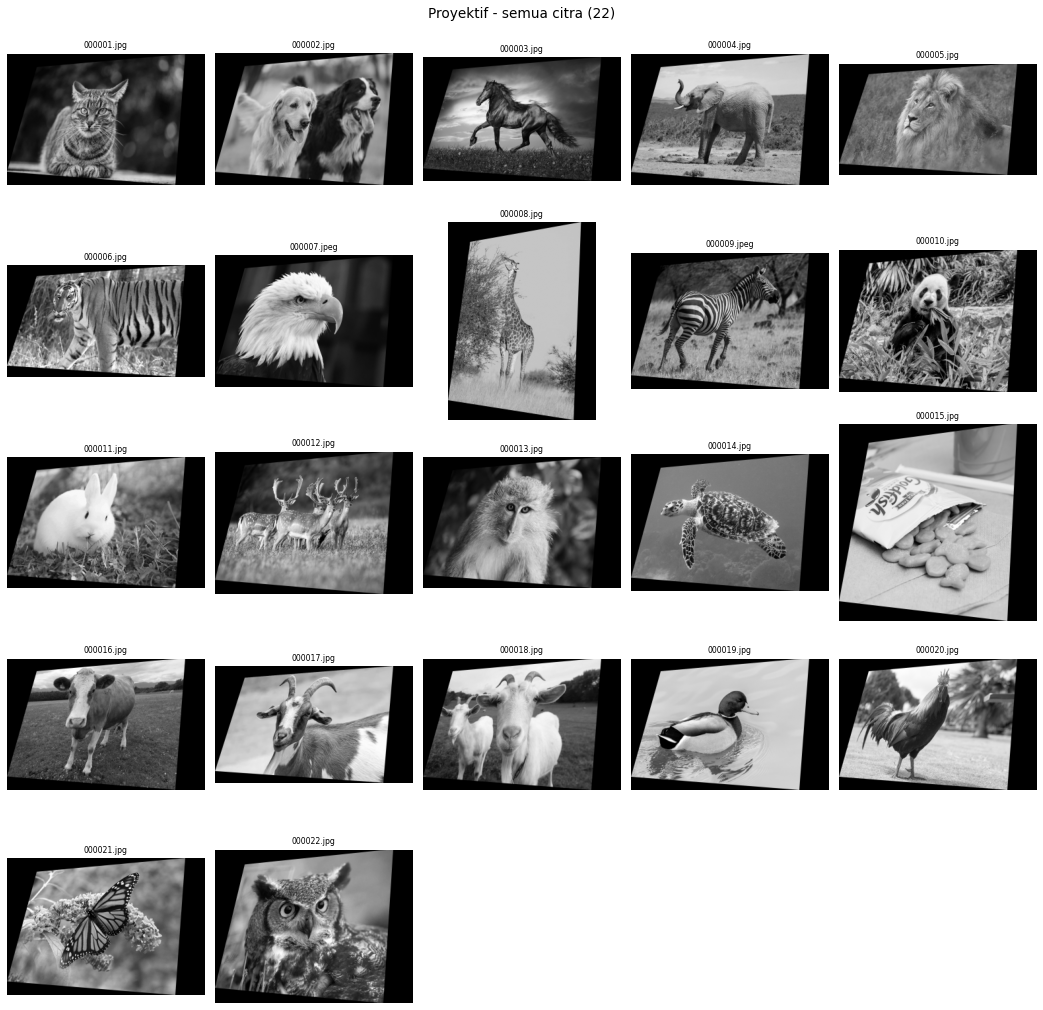

In [7]:
def tampilkan_semua(nama_transformasi, kolom=5):
    n = len(dataset)
    baris = int(np.ceil(n / kolom))
    plt.figure(figsize=(3 * kolom, 3 * baris), dpi=70)
    for i, (nama, _) in enumerate(dataset, 1):
        plt.subplot(baris, kolom, i)
        plt.imshow(kecilkan(hasil[nama][nama_transformasi]), cmap="gray", vmin=0, vmax=255)
        plt.title(nama[:18], fontsize=8)
        plt.axis("off")
    plt.suptitle(f"{nama_transformasi} - semua citra ({n})", fontsize=14)
    plt.tight_layout()
    plt.show()

for k in TRANSFORMASI:
    tampilkan_semua(k)

## 7. Penjelasan Singkat Matriks Transformasi

| Transformasi | Matriks / Fungsi OpenCV | Keterangan |
|---|---|---|
| Translasi | `[[1,0,tx],[0,1,ty]]` + `warpAffine` | Menggeser posisi piksel |
| Rotasi | `getRotationMatrix2D` + `warpAffine` | Memutar terhadap pusat citra, kanvas diperluas agar tidak terpotong |
| Scaling | `resize(fx, fy)` | `INTER_AREA` untuk pengecilan, `INTER_LINEAR` untuk pembesaran |
| Shearing | `[[1,shx,0],[shy,1,0]]` + `warpAffine` | Memiringkan citra searah sumbu x/y |
| Refleksi | `flip(kode)` | 1 = horizontal, 0 = vertikal, -1 = keduanya |
| Affine | `getAffineTransform` (3 titik) | Mempertahankan garis sejajar |
| Proyektif | `getPerspectiveTransform` (4 titik) | Mengubah sudut pandang, garis sejajar tidak harus tetap sejajar |